In [1]:
from anemone.inversion import *
from anemone.forwards import Forward, logify_forward
from anemone.system import Loop, Receiver, Waveform, FilterChain, ButterworthFilter
from anemone.experiment import compute_relstd

In [2]:

logForward = logify_forward(Forward)

times = torch.logspace(-5,-2, 32, dtype=torch.float64)
fwrTD = logForward.example(times=times, tolerance=1e-6)

rho = torch.tensor([20, 80, 40])
thk = torch.tensor([30,40.])
mod_true = LogResistivity.few_layers(rho, thk)


dbdt_true = fwrTD(rho, thk).exp()
d_relerr = compute_relstd(fwrTD.times, dbdt_true, current=10.)
d_err = torch.log1p(d_relerr)
d_obs = dbdt_true + dbdt_true * torch.randn_like(dbdt_true) * d_relerr

d_obs = torch.abs(d_obs).log()


t_max = max([fwr.times.max().item() for fwr in [fwrTD]])
d_max = (t_max*4e6)**0.5
n_layers = 30

thk = 1.+torch.logspace(-0.5, np.log10(d_max-n_layers+1), n_layers).diff()
z = thk.cumsum(0)
res_start=LogResistivity.smooth(torch.ones(n_layers)*100., z)

C:\Users\au646858\OneDrive - Aarhus Universitet\Documents\_repositories\anemone\src\anemone\experiment\experiment.py:11: UserWarning: The use of `x.T` on tensors of dimension other than 2 to reverse their shape is deprecated and it will throw an error in a future release. Consider `x.mT` to transpose batches of matrices or `x.permute(*torch.arange(x.ndim - 1, -1, -1))` to reverse the dimensions of a tensor. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\TensorShape.cpp:4424.)
  std_rel = abs_noise/y.T


001	misfit:	8.83
002	misfit:	2.75
003	misfit:	1.03
004	misfit:	1.01
005	misfit:	1.00
006	misfit:	0.99
007	misfit:	0.99
008	misfit:	0.99
009	misfit:	0.99
010	misfit:	0.99
reached iteration cap..


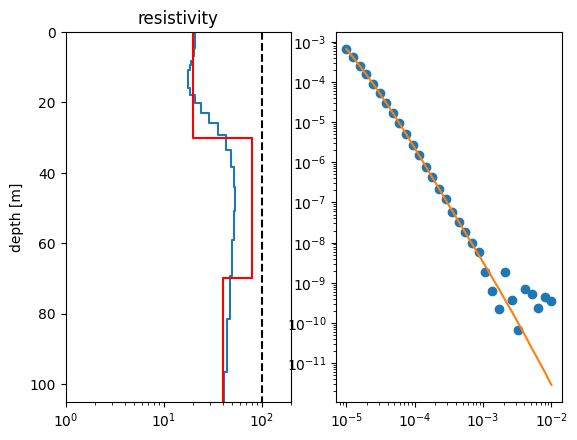

In [3]:
import matplotlib.pyplot as plt
fig,axs = plt.subplots(1,2)
ax = res_start.plot(axs=axs[:1], color='black', linestyle='--')

fastJac = fastjacobian(Tikhonov)

inv = fastJac(d_obs, d_err, res_start.copy(), fwrTD)
inv.data_misfit_acceptance_threshold = 0.9
res_mod = inv.invert(iter_cap=10)        




ax = res_mod.plot(axs=axs[:1])
mod_true.plot(axs=axs[:1], color='red', label='True model')

d_pred = fwrTD(*res_mod.mod)
axs[1].loglog(fwrTD.times, d_obs.exp(), 'o', label='Observed')
axs[1].loglog(fwrTD.times, d_pred.exp(), '-', label='Predicted')
axs[0].set_xlim(1, 200)
axs[0].set_xscale('log')
plt.show()

In [12]:
inv.save("inversion.json")

In [9]:
inv2.starting_model.description = inv.starting_model.description
inv2.final_model.description = inv.final_model.description

inv==inv2

False

In [10]:
print(inv)

fastjacobian.<locals>.FastJacobian(data_observed=tensor([ -7.3242,  -7.8110,  -8.2937,  -8.7860,  -9.3305,  -9.8666, -10.4001,
        -10.9730, -11.5474, -12.1785, -12.8479, -13.4226, -14.0837, -14.6418,
        -15.3525, -15.9258, -16.6703, -17.2490, -17.7857, -18.4303, -18.9555,
        -20.1046, -21.1975, -22.2176, -20.1120, -21.7186, -23.4125, -21.0752,
        -21.3457, -22.1839, -21.5524, -21.7539], dtype=torch.float64), data_error=tensor([0.0296, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296,
        0.0296, 0.0296, 0.0296, 0.0297, 0.0301, 0.0310, 0.0337, 0.0400, 0.0544,
        0.0812, 0.1281, 0.2053, 0.3237, 0.5083, 0.7557, 1.1061, 1.5108, 2.0072,
        2.5335, 3.1243, 3.6985, 4.2927, 4.9258], dtype=torch.float64), starting_model=logify.<locals>.LogModel(values=[tensor([20.9858, 20.9817, 20.9435, 20.8348, 20.6192, 20.2693, 19.7774, 19.1687,
        18.5126, 17.9309, 17.6002, 17.7522, 18.6738, 20.7021, 24.1830, 29.3230,
        35.8887, 42.9164, 48.8769, 52.

In [11]:
print(inv2)

fastjacobian.<locals>.FastJacobian(data_observed=tensor([ -7.3242,  -7.8110,  -8.2937,  -8.7860,  -9.3305,  -9.8666, -10.4001,
        -10.9730, -11.5474, -12.1785, -12.8479, -13.4226, -14.0837, -14.6418,
        -15.3525, -15.9258, -16.6703, -17.2490, -17.7857, -18.4303, -18.9555,
        -20.1046, -21.1975, -22.2176, -20.1120, -21.7186, -23.4125, -21.0752,
        -21.3457, -22.1839, -21.5524, -21.7539], dtype=torch.float64), data_error=tensor([0.0296, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296, 0.0296,
        0.0296, 0.0296, 0.0296, 0.0297, 0.0301, 0.0310, 0.0337, 0.0400, 0.0544,
        0.0812, 0.1281, 0.2053, 0.3237, 0.5083, 0.7557, 1.1061, 1.5108, 2.0072,
        2.5335, 3.1243, 3.6985, 4.2927, 4.9258], dtype=torch.float64), starting_model=BaseModel(values=[tensor([20.9858, 20.9817, 20.9435, 20.8348, 20.6192, 20.2693, 19.7774, 19.1687,
        18.5126, 17.9309, 17.6002, 17.7522, 18.6738, 20.7021, 24.1830, 29.3230,
        35.8887, 42.9164, 48.8769, 52.4890, 53.4856, 

In [7]:
! code final_model.json

In [12]:
from anemone.inversion.models import BaseModel
m1 = BaseModel.load("final_model.json")

In [23]:
%%timeit

thk = 1.+torch.logspace(-0.5, np.log10(d_max-n_layers+1), n_layers).diff()
z = thk.cumsum(0)
res_start=LogResistivity.smooth(torch.ones(n_layers)*100., z)

277 µs ± 30.7 µs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [22]:
%%timeit
m1 = BaseModel.load("final_model.json")

1.93 ms ± 203 µs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


[<Axes: title={'center': 'physical_property_0'}, ylabel='depth [m]'>]

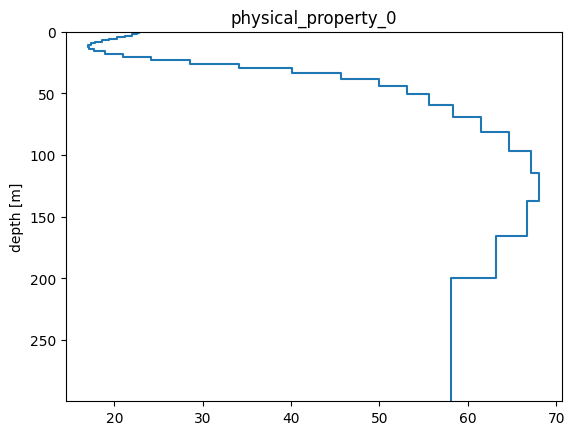

In [13]:
m1.plot()

In [3]:
import numpy as np
from typing import List
import json_numpy as jn

@jn.jsonable_dataclass
class MyClass:
    array: np.ndarray
    floats: List[float]
    names:  List[str]
    description: str = "This is my class"

In [20]:
MyClass(array=np.array([1,2,3]), floats=[1.0, 2.0, 3.0], names=['a','b','c']).save("myclass.json")


In [21]:
%%timeit
m2 = MyClass.load("myclass.json")

899 µs ± 32.8 µs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [ ]:
! code myclass.json

In [5]:
m2

MyClass(array=array([1, 2, 3]), floats=[1.0, 2.0, 3.0], names=['a', 'b', 'c'], description='myclass.json')